# DeepFreq Finetuning Notebook 🎵

## What This Notebook Does
Imagine you have a smart robot 🤖 that can identify musical notes from songs. This robot is already trained, but you want to make it even smarter by teaching it with MORE examples. That's what this notebook does! 

Think of it like:
- **Before**: The robot went to school and learned the basics (pretrained)
- **Now**: We're sending it to extra tutoring classes with MORE examples (finetuning)
- **Result**: The robot becomes a music expert! 🎓

## What's a Frequency?
A frequency is how fast something vibrates. When you hear a musical note, each note has a different frequency:
- Lower notes (like a deep bass sound 🔊) have LOW frequencies  
- Higher notes (like a bird chirping 🐦) have HIGH frequencies

## What DeepFreq Does
DeepFreq is like a smart ear 👂 that listens to sound with noise and figures out:
1. **FR Module** (Frequency Representation): "What musical notes are in the sound?" - Shows them on a graph 📊
2. **FC Module** (Frequency Counting): "How many different musical notes are there?" - Counts them ✋

## Step-by-Step Plan
1. Load the already-trained models (the smart robot that already knows stuff)
2. Create practice examples with noise (more training data)
3. Teach the models with the new examples (finetuning - learning even more)
4. Check how well the models are learning (validation - taking a test)
5. Save the improved models (save the smarter robot)

In [1]:
import os
import sys
import numpy as np
import torch
import torch.nn as nn
from torch.utils.tensorboard import SummaryWriter
import logging
import time
import argparse

# Import DeepFreq modules
import util
import modules
from data import dataset, fr, loss as loss_module, noise

# Setup logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.13.0
CUDA available: False


## Step 1: Setup - Tell the Computer What We Want ⚙️

Before we start training, we need to tell the computer all the rules and settings:

🎯 **What settings do we need?**
- **Where are the saved models?** (checkpoint paths) - Like finding the textbook we need
- **How many practice examples?** - Like deciding how many homework problems to do
- **How fast should the robot learn?** (learning rate) - Like choosing how many hours of tutoring per day
- **Where should we save the improved models?** - Where to put the results

This is like setting up the rules of a game BEFORE playing - everything needs to be ready! 🎮

In [2]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_cuda = torch.cuda.is_available()

# Paths
fr_checkpoint = 'pretrained_models/DeepFreq/frequency_representation_module.pth'
fc_checkpoint = 'pretrained_models/DeepFreq/frequency_counting_module.pth'
output_dir = 'checkpoint/finetune_experiment'

# Create output directory
os.makedirs(output_dir, exist_ok=True)

# Finetuning hyperparameters
finetuning_config = {
    'batch_size': 128,
    'n_training': 10000,      # Additional training samples
    'n_validation': 2000,     # Validation samples
    'n_epochs_fr': 10,        # FR module finetuning epochs
    'n_epochs_fc': 10,        # FC module finetuning epochs
    'lr_fr': 1e-4,            # Reduced LR for finetuning FR
    'lr_fc': 1e-4,            # Reduced LR for finetuning FC
    'snr': 1.0,               # SNR for training
    'noise': 'gaussian_blind',
    'signal_dim': 50,
    'fr_size': 1000,
    'max_n_freq': 10,
    'min_sep': 1.0,
    'distance': 'normal',
    'amplitude': 'normal_floor',
    'floor_amplitude': 0.1,
    'kernel_type': 'gaussian',
    'gaussian_std': 0.3,
}

print("Finetuning Configuration:")
for key, value in finetuning_config.items():
    print(f"  {key}: {value}")

Finetuning Configuration:
  batch_size: 128
  n_training: 10000
  n_validation: 2000
  n_epochs_fr: 10
  n_epochs_fc: 10
  lr_fr: 0.0001
  lr_fc: 0.0001
  snr: 1.0
  noise: gaussian_blind
  signal_dim: 50
  fr_size: 1000
  max_n_freq: 10
  min_sep: 1.0
  distance: normal
  amplitude: normal_floor
  floor_amplitude: 0.1
  kernel_type: gaussian
  gaussian_std: 0.3


## Step 2: Load the Pre-trained Models 📦

Just like loading a save file in a video game, we're loading the models that were already trained before.

🧠 **We're loading TWO models:**
1. **FR Module** (Frequency Representation): The part that finds WHERE the musical notes are located 📍
2. **FC Module** (Frequency Counting): The part that counts HOW MANY different musical notes are there 🔢

Think of it like this:
- **FR = Homework student who can find all the questions** (finds the notes)
- **FC = Homework student who can count answers** (counts the notes)

These models are like students who already went to school and learned some basics. 📚 Now we're going to send them to EXTRA TUTORING to make them even smarter! 💪

In [3]:
# Load FR module
fr_module, fr_optimizer, fr_scheduler, args_fr, epoch_fr = util.load(
    fr_checkpoint, 'fr', device
)
print(f"Loaded FR module from {fr_checkpoint}")
print(f"  Last training epoch: {epoch_fr}")
print(f"  Number of parameters: {util.model_parameters(fr_module)}")

# Load FC module
fc_module, fc_optimizer, fc_scheduler, args_fc, epoch_fc = util.load(
    fc_checkpoint, 'fc', device
)
print(f"\nLoaded FC module from {fc_checkpoint}")
# Override checkpoint paths so finetuned models are saved locally
args_fr.output_dir = output_dir
args_fc.output_dir = output_dir
print(f"  Last training epoch: {epoch_fc}")
print(f"  Number of parameters: {util.model_parameters(fc_module)}")

Loaded FR module from pretrained_models/DeepFreq/frequency_representation_module.pth
  Last training epoch: 300
  Number of parameters: 1049920

Loaded FC module from pretrained_models/DeepFreq/frequency_counting_module.pth
  Last training epoch: 300
  Number of parameters: 63786


## Step 3: Create Practice Examples 📚

Just like you need homework problems to practice math, we need practice examples to teach the models.

📖 **Training Data (10,000 examples)**: 
- These are the HOMEWORK PROBLEMS we use to teach the models
- We add noise (background sound) to make them challenging
- It's like trying to hear someone on a phone call in a NOISY CAFE ☕ - realistic and hard!
- The models learn from these examples and improve

✅ **Validation Data (2,000 examples)**: 
- These are the TEST QUESTIONS we use to check if the models are learning correctly
- We DON'T teach with these - we just TEST with them
- It's like a pop quiz to see if the students actually learned! 📝

💡 **Why add noise?**
Because in real life, sound ALWAYS has noise! 🌆
- Training with noise makes the models smarter at handling real-world situations
- It's like practicing basketball while people are cheering in the crowd (realistic) vs. in an empty gym (fake)

In [4]:
# Create frequency grid
xgrid = np.linspace(-0.5, 0.5, finetuning_config['fr_size'], endpoint=False)

# Generate training data
print("Generating training data...")
train_loader = dataset.load_dataloader(
    num_samples=finetuning_config['n_training'],
    signal_dim=finetuning_config['signal_dim'],
    max_n_freq=finetuning_config['max_n_freq'],
    min_sep=finetuning_config['min_sep'],
    distance=finetuning_config['distance'],
    amplitude=finetuning_config['amplitude'],
    floor_amplitude=finetuning_config['floor_amplitude'],
    kernel_type=finetuning_config['kernel_type'],
    kernel_param=finetuning_config['gaussian_std'] / finetuning_config['signal_dim'],
    batch_size=finetuning_config['batch_size'],
    xgrid=xgrid
)
print(f"Training data: {finetuning_config['n_training']} samples")

# Generate validation data
print("Generating validation data...")
val_loader = dataset.load_dataloader_fixed_noise(
    num_samples=finetuning_config['n_validation'],
    signal_dim=finetuning_config['signal_dim'],
    max_n_freq=finetuning_config['max_n_freq'],
    min_sep=finetuning_config['min_sep'],
    distance=finetuning_config['distance'],
    amplitude=finetuning_config['amplitude'],
    floor_amplitude=finetuning_config['floor_amplitude'],
    kernel_type=finetuning_config['kernel_type'],
    kernel_param=finetuning_config['gaussian_std'] / finetuning_config['signal_dim'],
    batch_size=finetuning_config['batch_size'],
    xgrid=xgrid,
    snr=finetuning_config['snr'],
    noise=finetuning_config['noise']
)
print(f"Validation data: {finetuning_config['n_validation']} samples")

Generating training data...
Training data: 10000 samples
Generating validation data...
Validation data: 2000 samples


## Step 4: Prepare the Learning Tools 🛠️

Now we give the models the right tools to learn:

👨‍🏫 **Optimizer (Adam - The Smart Teacher)**: 
- This is like a teacher who helps the model improve
- It looks at mistakes and adjusts the model's "brain" to make fewer mistakes next time
- **Learning Rate** (1e-4 = very small!): How much the teacher adjusts things
  - We use a TINY learning rate because the models already know stuff
  - Like fine-tuning a guitar that's already in tune - you make SMALL adjustments! 🎸
  
📊 **Loss Function (The Report Card)**:
- This measures "How wrong is the model?" 
- Lower numbers = better! (Just like your report card!)
- For FR: We use MSE (Mean Squared Error) - measures if the frequency map is correct
- For FC: We use MSE - measures if the frequency count is correct

🎯 **Scheduler (The Strict Teacher)**:
- This is like a teacher who gets stricter if the student stops improving
- If the model isn't making progress, we REDUCE the learning rate to be more careful
- It's like: "Hey, you stopped learning! Let me make the lessons EASIER so you can catch up!" 📉➡️📈

In [5]:
# Create new optimizers for finetuning with reduced learning rates
fr_optimizer = torch.optim.Adam(fr_module.parameters(), lr=finetuning_config['lr_fr'])
fc_optimizer = torch.optim.Adam(fc_module.parameters(), lr=finetuning_config['lr_fc'])

# Learning rate schedulers
fr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    fr_optimizer, 'min', patience=5, factor=0.5
)
fc_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    fc_optimizer, 'min', patience=5, factor=0.5
)

# Loss functions
fr_criterion = nn.MSELoss()
fc_criterion = nn.MSELoss()  # Regression loss

print("Optimizers and loss functions configured")

Optimizers and loss functions configured


## Step 5: The Teaching Functions 📖

These are the CORE teaching functions. Think of them as the homework-solving process:

### train_fr_epoch() - Teaching the Frequency Finder 🔍

**What does "epoch" mean?** 
- One complete pass through ALL the practice examples
- Like reading through an entire chapter of a book once ✓

**What happens in one epoch?**
1. Give it a CLEAN sound and a NOISY sound 🔊
2. The model listens to the NOISY sound (realistic! Like real life!) 
3. The model draws a frequency map: "Here's where the musical notes are!" 📍
4. We compare its map to the TRUE frequency map
5. If it's wrong, we adjust the model to be better (using the optimizer)
6. We repeat with ALL 10,000 practice examples

**FNR (False Negative Rate)** = "Did the model MISS any notes?" 
- Lower is better! ✅ (We want to find ALL the notes!)
- It's like a teacher checking: "Did you find all the answers on the test?"

### train_fc_epoch() - Teaching the Frequency Counter 🔢

**What happens in one epoch?**
1. Give it a sound 🎵
2. First, use the FR module to get the frequency map (we already trust FR is working!)
3. Then, let FC module count: "How many notes are in this map?" 
4. Compare with the TRUE count
5. If FC is wrong, adjust it to be better
6. Repeat with ALL 10,000 examples

**Accuracy** = "Did the model count the RIGHT number of notes?"
- Higher is better! ✅ (Like getting more answers correct on a test!)
- 100% accuracy = perfect score! 🏆

**Why do we train FR first, then FC?**
- It's like learning alphabet BEFORE spelling words
- FR needs to be good first, then FC can learn to count the good results!

In [6]:
def train_fr_epoch(fr_module, fr_optimizer, fr_criterion, train_loader, val_loader, xgrid, epoch):
    """
    Train FR module for one epoch
    """
    epoch_start_time = time.time()
    fr_module.train()
    loss_train_fr = 0
    
    for batch_idx, (clean_signal, target_fr, freq) in enumerate(train_loader):
        if use_cuda:
            clean_signal, target_fr = clean_signal.cuda(), target_fr.cuda()
        
        # Add noise
        noisy_signal = noise.noise_torch(clean_signal, finetuning_config['snr'], finetuning_config['noise'])
        
        fr_optimizer.zero_grad()
        output_fr = fr_module(noisy_signal)
        loss_fr = fr_criterion(output_fr, target_fr)
        loss_fr.backward()
        fr_optimizer.step()
        
        loss_train_fr += loss_fr.data.item()
    
    # Validation
    fr_module.eval()
    loss_val_fr, fnr_val = 0, 0
    
    with torch.no_grad():
        for batch_idx, (noisy_signal, _, target_fr, freq) in enumerate(val_loader):
            if use_cuda:
                noisy_signal, target_fr = noisy_signal.cuda(), target_fr.cuda()
            
            output_fr = fr_module(noisy_signal)
            loss_fr = fr_criterion(output_fr, target_fr)
            loss_val_fr += loss_fr.data.item()
            
            # Compute FNR (false negative rate)
            nfreq = (freq >= -0.5).sum(dim=1)
            f_hat = fr.find_freq(output_fr.cpu().numpy(), nfreq, xgrid)
            fnr_val += loss_module.fnr(f_hat, freq.cpu().numpy(), finetuning_config['signal_dim'])
    
    loss_train_fr /= len(train_loader.dataset) / finetuning_config['batch_size']
    loss_val_fr /= len(val_loader.dataset) / finetuning_config['batch_size']
    fnr_val *= 100 / (len(val_loader.dataset) / finetuning_config['batch_size'])
    
    fr_scheduler.step(loss_val_fr)
    
    elapsed = time.time() - epoch_start_time
    logger.info(f"FR Epoch {epoch}: Time {elapsed:.1f}s, Train L2 {loss_train_fr:.4f}, Val L2 {loss_val_fr:.4f}, FNR {fnr_val:.2f}%")
    
    return loss_train_fr, loss_val_fr, fnr_val


def train_fc_epoch(fr_module, fc_module, fc_optimizer, fc_criterion, train_loader, val_loader, epoch):
    """
    Train FC module for one epoch
    """
    epoch_start_time = time.time()
    fr_module.eval()
    fc_module.train()
    loss_train_fc, acc_train_fc = 0, 0
    
    for batch_idx, (clean_signal, target_fr, freq) in enumerate(train_loader):
        if use_cuda:
            clean_signal, target_fr, freq = clean_signal.cuda(), target_fr.cuda(), freq.cuda()
        
        # Add noise
        noisy_signal = noise.noise_torch(clean_signal, finetuning_config['snr'], finetuning_config['noise'])
        
        # Get true frequency count
        nfreq = (freq >= -0.5).sum(dim=1).float()
        
        with torch.no_grad():
            output_fr = fr_module(noisy_signal)
            output_fr = output_fr.detach()
        
        output_fc = fc_module(output_fr)
        output_fc = output_fc.view(output_fc.size(0))
        
        loss_fc = fc_criterion(output_fc, nfreq)
        
        fc_optimizer.zero_grad()
        loss_fc.backward()
        fc_optimizer.step()
        
        # Accuracy (rounded prediction vs ground truth)
        estimate = torch.round(output_fc)
        acc_train_fc += estimate.eq(nfreq).sum().cpu().item()
        loss_train_fc += loss_fc.data.item()
    
    # Validation
    fc_module.eval()
    loss_val_fc, acc_val_fc = 0, 0
    
    with torch.no_grad():
        for batch_idx, (noisy_signal, _, target_fr, freq) in enumerate(val_loader):
            if use_cuda:
                noisy_signal, target_fr = noisy_signal.cuda(), target_fr.cuda()
            
            nfreq = (freq >= -0.5).sum(dim=1).float()
            if use_cuda:
                nfreq = nfreq.cuda()
            
            output_fr = fr_module(noisy_signal)
            output_fc = fc_module(output_fr)
            output_fc = output_fc.view(output_fc.size(0))
            
            loss_fc = fc_criterion(output_fc, nfreq)
            loss_val_fc += loss_fc.data.item()
            
            estimate = torch.round(output_fc)
            acc_val_fc += estimate.eq(nfreq).sum().item()
    
    n_train_batches = len(train_loader.dataset) / finetuning_config['batch_size']
    n_val_batches = len(val_loader.dataset) / finetuning_config['batch_size']
    
    loss_train_fc /= n_train_batches
    acc_train_fc *= 100 / len(train_loader.dataset)
    loss_val_fc /= n_val_batches
    acc_val_fc *= 100 / len(val_loader.dataset)
    
    fc_scheduler.step(loss_val_fc)
    
    elapsed = time.time() - epoch_start_time
    logger.info(f"FC Epoch {epoch}: Time {elapsed:.1f}s, Train Loss {loss_train_fc:.4f}, Val Loss {loss_val_fc:.4f}, "
                f"Train Acc {acc_train_fc:.2f}%, Val Acc {acc_val_fc:.2f}%")
    
    return loss_train_fc, loss_val_fc, acc_train_fc, acc_val_fc


print("Training functions defined")

Training functions defined


## Step 6: Teaching the Frequency Finder 👨‍🎓

Now we ACTUALLY TEACH the FR module to find notes better!

📚 **What happens here?**
- We repeat teaching 10 times (10 epochs)
- Each epoch, we show it all 10,000 practice examples
- Each example gets more noisy sounds added (different noise each time!)
- The FR module tries to find the notes, gets better each time

💾 **Saving Progress:**
- After every 5 epochs, we save the model (like saving your game progress!) 
- So if something goes wrong, we don't lose all the learning

📊 **What we track:**
- **Training Loss**: How wrong is it on the practice examples? (Should go DOWN ⬇️)
- **Validation Loss**: How wrong is it on the test examples? (Should go DOWN ⬇️)  
- **FNR (False Negative Rate)**: How many notes does it miss? (Should go DOWN ⬇️)

🎯 **Our Goal**: Make all three numbers get smaller! Better FR module = better at finding notes!

In [7]:
print("\n" + "="*60)
print("Starting FR Module Finetuning")
print("="*60)

# Ensure checkpoints are written to the local project directory
args_fr.output_dir = output_dir

fr_history = {'train_loss': [], 'val_loss': [], 'fnr': []}

for epoch in range(1, finetuning_config['n_epochs_fr'] + 1):
    train_loss, val_loss, fnr_val = train_fr_epoch(
        fr_module, fr_optimizer, fr_criterion, train_loader, val_loader, xgrid, epoch
    )
    
    fr_history['train_loss'].append(train_loss)
    fr_history['val_loss'].append(val_loss)
    fr_history['fnr'].append(fnr_val)
    
    # Save checkpoint every 5 epochs
    if epoch % 5 == 0:
        util.save(fr_module, fr_optimizer, fr_scheduler, args_fr, epoch_fr + epoch, 'fr')
        print(f"Saved FR checkpoint at epoch {epoch}")

print("\nFR Module Finetuning Complete!")


Starting FR Module Finetuning


INFO:__main__:FR Epoch 1: Time 42.5s, Train L2 0.0117, Val L2 0.0124, FNR 1485.79%
INFO:__main__:FR Epoch 2: Time 45.2s, Train L2 0.0118, Val L2 0.0124, FNR 1490.91%
INFO:__main__:FR Epoch 3: Time 45.0s, Train L2 0.0118, Val L2 0.0124, FNR 1488.06%
INFO:__main__:FR Epoch 4: Time 46.1s, Train L2 0.0116, Val L2 0.0124, FNR 1508.06%
INFO:__main__:FR Epoch 5: Time 46.3s, Train L2 0.0118, Val L2 0.0124, FNR 1494.34%


Saved FR checkpoint at epoch 5


INFO:__main__:FR Epoch 6: Time 46.1s, Train L2 0.0116, Val L2 0.0124, FNR 1482.34%
INFO:__main__:FR Epoch 7: Time 45.5s, Train L2 0.0116, Val L2 0.0124, FNR 1492.63%
INFO:__main__:FR Epoch 8: Time 45.2s, Train L2 0.0116, Val L2 0.0124, FNR 1478.63%
INFO:__main__:FR Epoch 9: Time 45.3s, Train L2 0.0115, Val L2 0.0124, FNR 1482.49%
INFO:__main__:FR Epoch 10: Time 45.1s, Train L2 0.0114, Val L2 0.0124, FNR 1500.03%


Saved FR checkpoint at epoch 10

FR Module Finetuning Complete!


## Step 7: Teaching the Frequency Counter 🧮

Now we teach the FC module to count notes better!

📚 **What happens here?**
- We repeat teaching 10 times (10 epochs)
- Each epoch, we show it all 10,000 practice examples
- The FC module tries to count the notes, gets better at counting each time

⚠️ **Important!**
- FR Module stays FROZEN (we don't change it anymore - it already learned enough!)
- We only teach FC to count using the good frequency maps from FR
- It's like: "FR found the notes, now FC learns to count them"

💾 **Saving Progress:**
- After every 5 epochs, we save the model (like saving your game progress!)

📊 **What we track:**
- **Training Loss**: How wrong is it on practice? (Should go DOWN ⬇️)
- **Validation Loss**: How wrong is it on tests? (Should go DOWN ⬇️)
- **Training Accuracy**: Percent correct on practice? (Should go UP ⬆️)
- **Validation Accuracy**: Percent correct on tests? (Should go UP ⬆️)

🎯 **Our Goal**: Make accuracy 100%! Perfect note counting! 🏆

In [8]:
print("\n" + "="*60)
print("Starting FC Module Finetuning")
print("="*60)

fc_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(1, finetuning_config['n_epochs_fc'] + 1):
    train_loss, val_loss, train_acc, val_acc = train_fc_epoch(
        fr_module, fc_module, fc_optimizer, fc_criterion, train_loader, val_loader, epoch
    )
    
    fc_history['train_loss'].append(train_loss)
    fc_history['val_loss'].append(val_loss)
    fc_history['train_acc'].append(train_acc)
    fc_history['val_acc'].append(val_acc)
    
    # Save checkpoint every 5 epochs
    if epoch % 5 == 0:
        util.save(fc_module, fc_optimizer, fc_scheduler, args_fc, epoch_fc + epoch, 'fc')
        print(f"Saved FC checkpoint at epoch {epoch}")

print("\nFC Module Finetuning Complete!")


Starting FC Module Finetuning


INFO:__main__:FC Epoch 1: Time 62.7s, Train Loss 1.7202, Val Loss 1.6510, Train Acc 38.80%, Val Acc 30.75%
INFO:__main__:FC Epoch 2: Time 62.9s, Train Loss 1.5456, Val Loss 1.9483, Train Acc 41.06%, Val Acc 21.35%
INFO:__main__:FC Epoch 3: Time 62.8s, Train Loss 1.5052, Val Loss 2.0877, Train Acc 42.92%, Val Acc 29.25%
INFO:__main__:FC Epoch 4: Time 66.7s, Train Loss 1.5005, Val Loss 1.6682, Train Acc 43.22%, Val Acc 46.60%
INFO:__main__:FC Epoch 5: Time 65.9s, Train Loss 1.4630, Val Loss 1.9585, Train Acc 44.57%, Val Acc 20.75%


Saved FC checkpoint at epoch 5


INFO:__main__:FC Epoch 6: Time 65.8s, Train Loss 1.4981, Val Loss 1.9071, Train Acc 44.26%, Val Acc 37.90%
INFO:__main__:FC Epoch 7: Time 70.4s, Train Loss 1.4592, Val Loss 1.6072, Train Acc 43.97%, Val Acc 38.10%
INFO:__main__:FC Epoch 8: Time 68.3s, Train Loss 1.5162, Val Loss 1.6079, Train Acc 43.20%, Val Acc 38.60%
INFO:__main__:FC Epoch 9: Time 67.2s, Train Loss 1.4703, Val Loss 1.6931, Train Acc 44.18%, Val Acc 46.30%
INFO:__main__:FC Epoch 10: Time 67.6s, Train Loss 1.4702, Val Loss 1.5859, Train Acc 44.71%, Val Acc 43.35%


Saved FC checkpoint at epoch 10

FC Module Finetuning Complete!


## Step 8: Draw Pictures of Learning 📊📈

Now let's make pretty graphs to see how well the teaching worked! 

### The 4 Graphs 📉

**📍 Top-Left: FR Training Loss** (Frequency Finder - How Wrong Is It?)
- Shows if FR is getting better or worse
- 🟦 Blue line = practice data (training)
- 🟧 Orange line = test data (validation)
- The line SHOULD go DOWN (lower loss = better!)
- It's like: "Is the student getting fewer questions wrong?" ✓

**📍 Top-Right: False Negative Rate** (Notes Missed?)
- Shows how many notes FR misses
- Green line = how many it forgets to find
- The line SHOULD go DOWN (fewer missed = better!)
- It's like: "Is the student finding all the problems?" ✓

**📍 Bottom-Left: FC Training Loss** (Frequency Counter - How Wrong Is It?)
- Shows if FC is getting better at counting
- 🟦 Blue line = practice (training)
- 🟧 Orange line = test (validation)
- The line SHOULD go DOWN ⬇️

**📍 Bottom-Right: FC Accuracy** (Counting Correct?)
- Shows what percentage of counts are CORRECT
- 🟦 Blue line = practice accuracy
- 🟧 Orange line = test accuracy
- The line SHOULD go UP ⬆️ (higher % = better!)

### What to Look For 👀

✅ **Good signs:**
- Training AND validation lines both go down/up (not just training)
- Lines smooth out and stop changing (learning is done!)

⚠️ **Bad signs:**
- Validation gets worse while training gets better = OVERFITTING 
  - It's like memorizing answers instead of understanding! 🤔
- Lines go up and down randomly = something's wrong

### Remember! 📝
- **Blue lines** = learning on homework (training)
- **Orange lines** = testing on a test (validation)
- We care about BOTH! If only training improves, the model is cheating! 😜

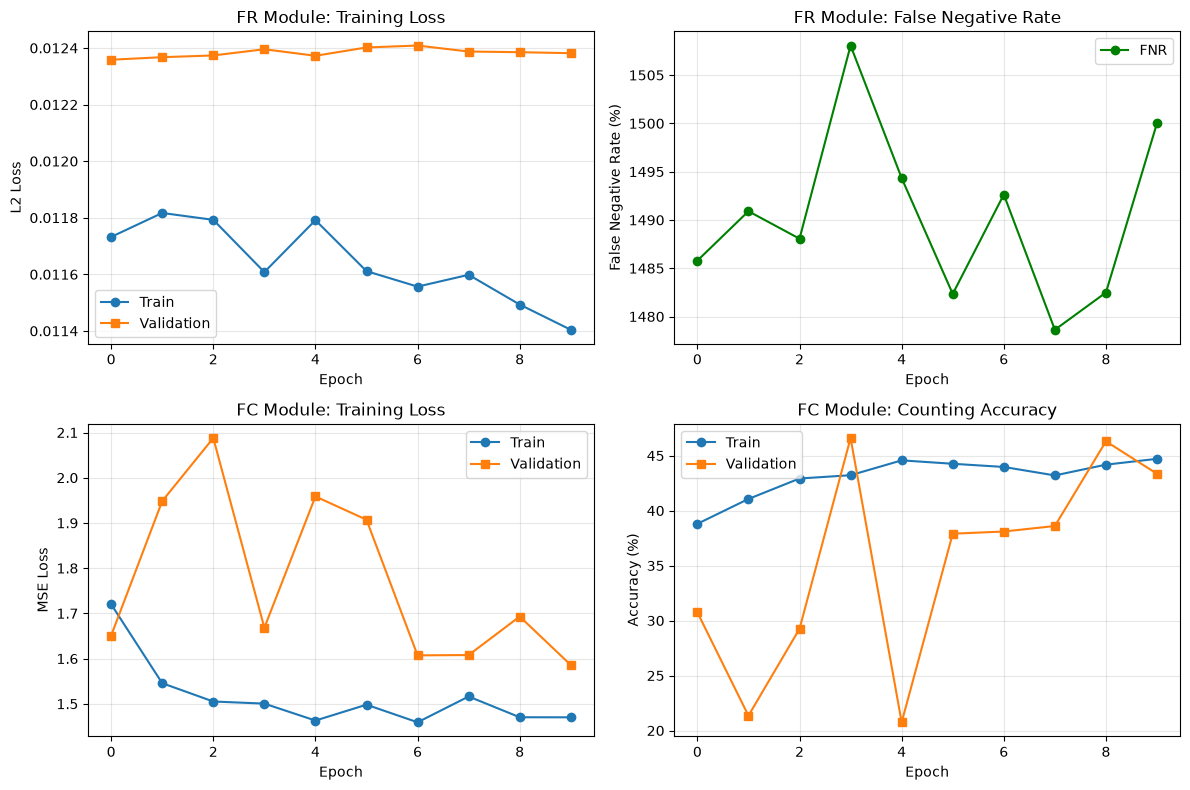


Training history plot saved to checkpoint/finetune_experiment/finetuning_history.png


In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# FR Loss
axes[0, 0].plot(fr_history['train_loss'], label='Train', marker='o')
axes[0, 0].plot(fr_history['val_loss'], label='Validation', marker='s')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('L2 Loss')
axes[0, 0].set_title('FR Module: Training Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# FR FNR
axes[0, 1].plot(fr_history['fnr'], label='FNR', marker='o', color='green')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('False Negative Rate (%)')
axes[0, 1].set_title('FR Module: False Negative Rate')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# FC Loss
axes[1, 0].plot(fc_history['train_loss'], label='Train', marker='o')
axes[1, 0].plot(fc_history['val_loss'], label='Validation', marker='s')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('MSE Loss')
axes[1, 0].set_title('FC Module: Training Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# FC Accuracy
axes[1, 1].plot(fc_history['train_acc'], label='Train', marker='o')
axes[1, 1].plot(fc_history['val_acc'], label='Validation', marker='s')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].set_title('FC Module: Counting Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'finetuning_history.png'), dpi=150)
plt.show()

print(f"\nTraining history plot saved to {os.path.join(output_dir, 'finetuning_history.png')}")

## Step 9: Save the Final Models 💾

Now we save the FINAL improved models!

In [10]:
# Save final checkpoints
final_fr_epoch = epoch_fr + finetuning_config['n_epochs_fr']
final_fc_epoch = epoch_fc + finetuning_config['n_epochs_fc']

util.save(fr_module, fr_optimizer, fr_scheduler, args_fr, final_fr_epoch, 'fr')
print(f"Saved final FR checkpoint (epoch {final_fr_epoch})")

util.save(fc_module, fc_optimizer, fc_scheduler, args_fc, final_fc_epoch, 'fc')
print(f"Saved final FC checkpoint (epoch {final_fc_epoch})")

print(f"\nCheckpoints saved to: {output_dir}")

Saved final FR checkpoint (epoch 310)
Saved final FC checkpoint (epoch 310)

Checkpoints saved to: checkpoint/finetune_experiment


## Summary - What We Did! 🎉

### The Journey:
1. ✅ Loaded smart robots (pretrained models)
2. ✅ Created practice examples with noise (realistic training data)
3. ✅ Taught the robots with these examples (finetuning)
4. ✅ Watched them learn (validation and graphs)
5. ✅ Saved the smarter robots (final models)

### What We Learned:
- **FR Module**: Now BETTER at finding musical notes! 🎵
- **FC Module**: Now BETTER at counting notes! 🔢
- **Training with Noise**: Makes models work better in real life! 🌍

### What You Can Do Next:
- Run this notebook with DIFFERENT settings to see what works best
- Add your OWN audio data for even better learning
- Test the improved models on new sounds
- Experiment and have fun! 🚀

### Key Takeaway:
Finetuning = Extra tutoring for smart models! 📚➡️💪

In [11]:
print("\n" + "="*60)
print("FINETUNING SUMMARY")
print("="*60)

print(f"\nFR Module:")
print(f"  Final Training Loss: {fr_history['train_loss'][-1]:.6f}")
print(f"  Final Validation Loss: {fr_history['val_loss'][-1]:.6f}")
print(f"  Final FNR: {fr_history['fnr'][-1]:.2f}%")

print(f"\nFC Module:")
print(f"  Final Training Loss: {fc_history['train_loss'][-1]:.6f}")
print(f"  Final Validation Loss: {fc_history['val_loss'][-1]:.6f}")
print(f"  Final Training Accuracy: {fc_history['train_acc'][-1]:.2f}%")
print(f"  Final Validation Accuracy: {fc_history['val_acc'][-1]:.2f}%")

print(f"\nCheckpoint Location: {os.path.abspath(output_dir)}")
print(f"\nTo use the finetuned models in inference:")
print(f"  fr_path = '{os.path.join(output_dir, 'fr', 'last.pth')}'")
print(f"  fc_path = '{os.path.join(output_dir, 'fc', 'last.pth')}'")
print(f"  fr_module, _, _, args_fr, _ = util.load(fr_path, 'fr', device)")
print(f"  fc_module, _, _, args_fc, _ = util.load(fc_path, 'fc', device)")


FINETUNING SUMMARY

FR Module:
  Final Training Loss: 0.011404
  Final Validation Loss: 0.012382
  Final FNR: 1500.03%

FC Module:
  Final Training Loss: 1.470188
  Final Validation Loss: 1.585892
  Final Training Accuracy: 44.71%
  Final Validation Accuracy: 43.35%

Checkpoint Location: /Users/enqi/Workspace/python/DeepFreq/checkpoint/finetune_experiment

To use the finetuned models in inference:
  fr_path = 'checkpoint/finetune_experiment/fr/last.pth'
  fc_path = 'checkpoint/finetune_experiment/fc/last.pth'
  fr_module, _, _, args_fr, _ = util.load(fr_path, 'fr', device)
  fc_module, _, _, args_fc, _ = util.load(fc_path, 'fc', device)


In [ ]:
# Reload the saved fine-tuned checkpoints
checkpoint_path = os.path.join(output_dir, 'fr', 'last.pth')
print(checkpoint_path)
fr_module, fr_optimizer, fr_scheduler, args_fr, epoch_fr = util.load(
    checkpoint_path, 'fr', device
)

checkpoint_path = os.path.join(output_dir, 'fc', 'last.pth')
print(checkpoint_path)
fc_module, fc_optimizer, fc_scheduler, args_fc, epoch_fc = util.load(
    checkpoint_path, 'fc', device
)
